<a href="https://colab.research.google.com/github/Radiat09/colab/blob/main/Feature_Engineering(Starter%2C_Train_Test_Split_and_Missing_Value_Handling).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 3.2 Feature Engineering and Its Steps

**Feature Engineering** is the process of transforming raw data into meaningful, model-ready features (inputs) that better represent the underlying problem to predictive models—often improving accuracy more than switching algorithms.

---

### Core Steps in Feature Engineering

1. **Feature Inspection & Understanding**
   - Examine data types (numerical, categorical, datetime, text) and distributions.
   - Identify target leakage, irrelevant IDs, and domain meaning behind each column.

2. **Handling Missing Values**
   - **Imputation:** Fill numerical gaps with mean/median/KNN/iterative imputation; fill categorical gaps with mode or a dedicated `"Missing"` label.
   - **Indicator flags:** Add binary columns (`is_missing`) when missingness itself carries signal.
   - **Dropping:** Remove columns/rows with excessive missingness when safe.

3. **Encoding Categorical Variables**
   - **One-Hot Encoding:** For nominal (unordered) categories with low-to-moderate cardinality.
   - **Ordinal / Label Encoding:** Only when categories have a genuine rank/order (or for tree-based models where appropriate).
   - **Target / Frequency Encoding:** For high-cardinality categories (computed strictly inside cross-validation folds to prevent leakage).

4. **Feature Scaling & Normalization**
   - **Standardization (Z-score):** Zero mean, unit variance—great for linear models, SVMs, and neural networks.
   - **Min-Max Scaling / Robust Scaling:** Useful for bounded ranges or skewed data with outliers (`RobustScaler` uses median and IQR).
   - *Note:* Tree-based models (Random Forest, XGBoost, LightGBM) are largely invariant to monotonic scaling.

5. **Feature Transformation (Skewness & Outliers)**
   - Apply **log**, **Box-Cox**, or **Yeo-Johnson** transforms to reduce right/left skewness.
   - Cap/clip extreme outliers (winsorization) or transform them carefully so models aren't dominated by rare extremes.

6. **Feature Creation (Domain & Interaction Features)**
   - **Domain ratios/differences:** e.g., `debt_to_income`, `price_per_sqft`, `click_through_rate`.
   - **Datetime decomposition:** Extract `day_of_week`, `hour`, `is_weekend`, `month`, or elapsed time since an event.
   - **Aggregations:** Group-level statistics (mean/count/std per user or entity).
   - **Polynomial / Interaction terms:** Capturing non-linear relationships when needed.

7. **Feature Selection & Dimensionality Reduction**
   - **Filter methods:** Variance threshold, correlation with target, mutual information.
   - **Wrapper / Embedded methods:** Recursive Feature Elimination (RFE), L1 (Lasso) regularization, tree feature importances.
   - **Dimensionality reduction:** PCA or embeddings when dealing with high-dimensional or correlated features.

8. **Leakage Prevention & Pipeline Packaging**
   - Fit scalers, encoders, and imputers **only on training data** (or inside a `Pipeline` / `ColumnTransformer` during cross-validation).
   - Never use future information or target statistics from validation/test sets during fitting.

---

### Quick Rule of Thumb
> **Raw data sets the ceiling; clean, domain-informed features help the model reach it—without leaking test information.**

# 3.3 Feature Engineering Starter

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("titanic_data_updated.csv")
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,no,third,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,yes,first,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,yes,third,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,yes,first,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,no,third,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,no,second,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,yes,first,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,no,third,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,yes,first,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [4]:
# remove unnessesary columns
df.drop(["PassengerId","Name","Ticket"],axis=1, inplace=True)

In [5]:
df

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,no,third,male,22.0,1,0,7.2500,NaN,S
1,yes,first,female,38.0,1,0,71.2833,C85,C
2,yes,third,female,26.0,0,0,7.9250,NaN,S
3,yes,first,female,35.0,1,0,53.1000,C123,S
4,no,third,male,35.0,0,0,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...
886,no,second,male,27.0,0,0,13.0000,NaN,S
887,yes,first,female,19.0,0,0,30.0000,B42,S
888,no,third,female,NaN,1,2,23.4500,NaN,S
889,yes,first,male,26.0,0,0,30.0000,C148,C


In [7]:
df.isnull().sum()

,0
Survived,0
Pclass,0
Sex,0
Age,177
SibSp,0
Parch,0
Fare,0
Cabin,687
Embarked,2


In [8]:
# remove unnessesary columns
df.drop(["Cabin"],axis=1, inplace=True)

In [9]:
df

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,no,third,male,22.0,1,0,7.2500,S
1,yes,first,female,38.0,1,0,71.2833,C
2,yes,third,female,26.0,0,0,7.9250,S
3,yes,first,female,35.0,1,0,53.1000,S
4,no,third,male,35.0,0,0,8.0500,S
...,...,...,...,...,...,...,...,...
886,no,second,male,27.0,0,0,13.0000,S
887,yes,first,female,19.0,0,0,30.0000,S
888,no,third,female,NaN,1,2,23.4500,S
889,yes,first,male,26.0,0,0,30.0000,C


In [11]:
# split and select all the feature in a variable

x = df.drop(["Survived"], axis=1)
x

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,third,male,22.0,1,0,7.2500,S
1,first,female,38.0,1,0,71.2833,C
2,third,female,26.0,0,0,7.9250,S
3,first,female,35.0,1,0,53.1000,S
4,third,male,35.0,0,0,8.0500,S
...,...,...,...,...,...,...,...
886,second,male,27.0,0,0,13.0000,S
887,first,female,19.0,0,0,30.0000,S
888,third,female,NaN,1,2,23.4500,S
889,first,male,26.0,0,0,30.0000,C


In [12]:
# split the target feature column

y = df['Survived']
y

,Survived
0,no
1,yes
2,yes
3,yes
4,no
...,...
886,no
887,yes
888,no
889,yes


# 3.4 Train-Test Split Theory

**Train-Test Split** is the practice of partitioning a dataset into at least two disjoint subsets—a **training set** (used to fit/learn model parameters) and a **test set** (held out to provide an unbiased estimate of generalization on unseen data).

---

### Core Theory & Why It Matters

- **Generalization vs. Memorization:** A model evaluated on the same data it trained on can *overfit* (memorize noise) and appear overly accurate, failing in production.
- **Unbiased Performance Estimate:** The test set simulates future/unseen inputs and should only be touched **once** at the very end of model selection/tuning.
- **Train / Validation / Test Distinction:**
  - **Train set:** Learns weights, splits, or parameters.
  - **Validation set (or Cross-Validation folds):** Tunes hyperparameters and compares models without peeking at the test set.
  - **Test set:** Final, untouched benchmark before deployment.

---

### Key Split Ratios & Considerations

| Dataset Size | Typical Split | Notes |
|---|---|---|
| **Large** (100k+ rows) | `80/20`, `90/10`, or `98/1/1` (train/val/test) | Even a small test set still has thousands of samples for reliable metrics. |
| **Medium** (1k–100k rows) | `80/20` or `70/30` (often paired with k-fold CV on train) | Balances learning signal against evaluation variance. |
| **Small** (< 1k rows) | Stratified k-fold CV or repeated splits | Single holdout splits can have high variance/luck. |

---

### Important Splitting Strategies & Pitfalls

1. **Stratified Split (`stratify=y`)**
   - Preserves class proportions across train and test sets—essential for **imbalanced classification** so rare classes aren't missing from test or train.

2. **Data Leakage (The #1 Trap)**
   - Fitting scalers, imputers, encoders, or feature selectors on the **entire dataset before splitting** leaks test distribution info into training.
   - **Rule:** Split first; fit preprocessing strictly on training data (or inside CV folds).

3. **Grouped Data (`GroupShuffleSplit` / `GroupKFold`)**
   - When multiple rows belong to the same entity (e.g., same patient, user, or store), random splitting puts the same entity in both train and test—inflating accuracy. Group by entity ID when splitting.

4. **Time-Series / Temporal Data**
   - Never shuffle future data into the past. Split chronologically (e.g., train on earlier months, test on later months) or use **TimeSeriesSplit** / rolling walk-forward validation.

5. **Random Seed (`random_state`)**
   - Fix a seed during experimentation for reproducibility, then verify stability across seeds or cross-validation folds.

---

### Quick Rule of Thumb
> **Split before preprocessing, respect group and time boundaries, and treat the test set as sacred until the final check.**

# 3.5 Train_Test Split Code

In [14]:
X_train, X_test, Y_train, Y_test = train_test_split(x,y, test_size=0.2, random_state=42)

In [22]:
X_test

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
709,third,male,NaN,1,1,15.2458,C
439,second,male,31.0,0,0,10.5000,S
840,third,male,20.0,0,0,7.9250,S
720,second,female,6.0,0,1,33.0000,S
39,third,female,14.0,1,0,11.2417,C
...,...,...,...,...,...,...,...
433,third,male,17.0,0,0,7.1250,S
773,third,male,NaN,0,0,7.2250,C
25,third,female,38.0,1,5,31.3875,S
84,second,female,17.0,0,0,10.5000,S


# 3.6 Handling Missing Values

**Missing Values** occur when data is absent for a variable or observation (`NaN`, `None`, `NaT`, empty strings, or sentinel codes like `-999`). How you handle them directly impacts model bias, variance, and data leakage.

---

### Why Values Go Missing (Missingness Mechanisms)

1. **MCAR (Missing Completely at Random):** Missingness has no relationship to observed or unobserved data (e.g., a random sensor drop). Dropping or simple imputation rarely introduces structural bias if sample size is adequate.
2. **MAR (Missing at Random):** Missingness relates to other *observed* features (e.g., men being less likely to report a survey item, predictable from gender/age). Model-based or group-aware imputation works well.
3. **MNAR (Missing Not at Random):** Missingness depends on the *unobserved value itself* (e.g., high earners skipping income questions). Often requires domain handling, missingness indicator flags, or specialized modeling.

---

### Core Strategies for Handling Missing Values

#### 1. Dropping Rows or Columns
- **Drop rows:** Useful when missingness is small and MCAR/MAR, leaving plenty of data. Avoid dropping rows if it distorts class balance or shrinks small datasets.
- **Drop columns:** Consider when a feature has a very high missing rate (e.g., > 60–80%) or adds little predictive value after checking domain relevance.

#### 2. Simple Statistical Imputation
- **Mean:** Fast for roughly symmetric numerical distributions without heavy outliers.
- **Median:** Safer for **skewed numerical** data or distributions with outliers.
- **Mode / Constant (`"Missing"`):** Standard for categorical variables; creating an explicit `"Missing"` category preserves missingness as a distinct group.

#### 3. Multivariate & Model-Based Imputation
- **KNN Imputer:** Estimates missing values from the *k* nearest neighbors in feature space (scale features first and fit only on training data).
- **Iterative Imputer (MICE):** Models each feature with missing values as a function of other features in rounds.

#### 4. Missingness Indicator Flags (`add_indicator=True`)
- Adds a binary column (`1` if missing, `0` if present) alongside imputation.
- Especially helpful when **MNAR** is suspected or when missingness itself signals a status (e.g., missing `last_purchase_date` for a brand-new user).

---

### Data Leakage & Pipeline Rules

- **Split first, impute second:** Always compute means, medians, modes, or KNN/iterative imputers on the **training set** (or inside CV folds), then apply that fitted transformer to validation and test sets.
- **Watch

# 3.7 Numerical Missing value Imputation using Pandas

In [23]:
X_train.isnull().sum()

,0
Pclass,0
Sex,0
Age,140
SibSp,0
Parch,0
Fare,0
Embarked,2


In [24]:
X_test.isnull().sum()

,0
Pclass,0
Sex,0
Age,37
SibSp,0
Parch,0
Fare,0
Embarked,0


In [30]:
# Mean impute

age_mean=X_train["Age"].mean()

X_train["age_mean_imputor"] = X_train['Age'].fillna(age_mean)

# X_train.isnull().sum()
X_train


X_test["age_mean_imputor"] = X_test['Age'].fillna(age_mean)

X_test

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,age_mean_imputor
709,third,male,NaN,1,1,15.2458,C,29.498846
439,second,male,31.0,0,0,10.5000,S,31.000000
840,third,male,20.0,0,0,7.9250,S,20.000000
720,second,female,6.0,0,1,33.0000,S,6.000000
39,third,female,14.0,1,0,11.2417,C,14.000000
...,...,...,...,...,...,...,...,...
433,third,male,17.0,0,0,7.1250,S,17.000000
773,third,male,NaN,0,0,7.2250,C,29.498846
25,third,female,38.0,1,5,31.3875,S,38.000000
84,second,female,17.0,0,0,10.5000,S,17.000000


In [31]:
# Median impute

age_median=X_train["Age"].median()

X_train["age_median_imputor"] = X_train['Age'].fillna(age_median)

# X_train.isnull().sum()
X_train


X_test["age_median_imputor"] = X_test['Age'].fillna(age_median)

X_test

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,age_mean_imputor,age_median_imputor
709,third,male,NaN,1,1,15.2458,C,29.498846,28.0
439,second,male,31.0,0,0,10.5000,S,31.000000,31.0
840,third,male,20.0,0,0,7.9250,S,20.000000,20.0
720,second,female,6.0,0,1,33.0000,S,6.000000,6.0
39,third,female,14.0,1,0,11.2417,C,14.000000,14.0
...,...,...,...,...,...,...,...,...,...
433,third,male,17.0,0,0,7.1250,S,17.000000,17.0
773,third,male,NaN,0,0,7.2250,C,29.498846,28.0
25,third,female,38.0,1,5,31.3875,S,38.000000,38.0
84,second,female,17.0,0,0,10.5000,S,17.000000,17.0


<Axes: xlabel='age_mean_imputor', ylabel='Density'>

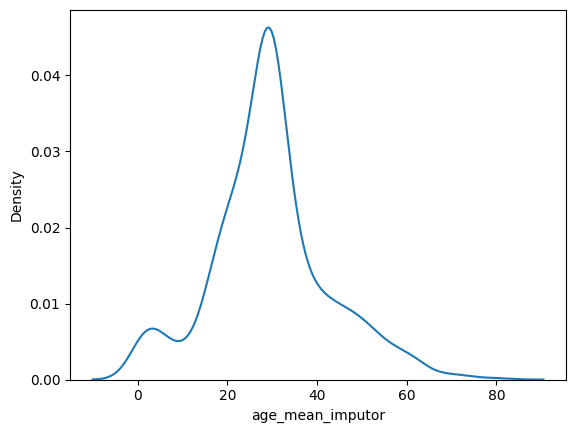

In [32]:
sns.kdeplot(data=X_train, x="age_mean_imputor")

<Axes: xlabel='age_median_imputor', ylabel='Density'>

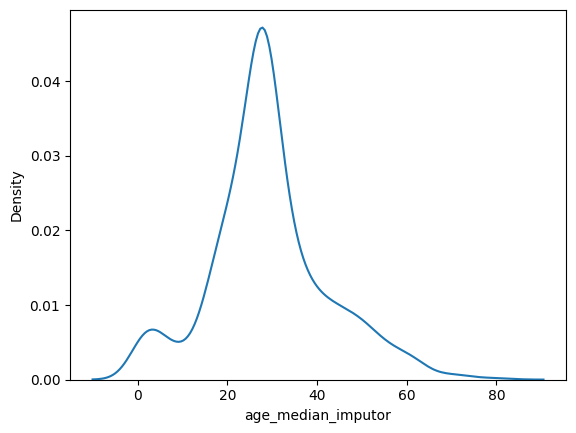

In [33]:
sns.kdeplot(data=X_train, x="age_median_imputor")

# 3.8 Numerical Missing Values Imputation using Simple Imputer

In [35]:
from sklearn.impute import SimpleImputer

age_imputer = SimpleImputer(missing_values=np.nan, strategy="mean")

age_imputer.fit(X_train[["Age"]])

X_train['Age'] =age_imputer.transform(X_train[["Age"]]).ravel()

In [39]:
X_train.isnull().sum()


X_train.drop(["age_mean_imputor","age_median_imputor"], axis=1,inplace=True)

X_train

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
331,first,male,45.500000,0,0,28.5000,S
733,second,male,23.000000,0,0,13.0000,S
382,third,male,32.000000,0,0,7.9250,S
704,third,male,26.000000,1,0,7.8542,S
813,third,female,6.000000,4,2,31.2750,S
...,...,...,...,...,...,...,...
106,third,female,21.000000,0,0,7.6500,S
270,first,male,29.498846,0,0,31.0000,S
860,third,male,41.000000,2,0,14.1083,S
435,first,female,14.000000,1,2,120.0000,S


In [43]:
X_test['Age'] =age_imputer.transform(X_test[["Age"]])

X_test.isnull().sum()

X_test.drop(["age_mean_imputor","age_median_imputor"], axis=1,inplace=True)


KeyError: "['age_mean_imputor', 'age_median_imputor'] not found in axis"

#3.9 Categorical Value Imputation with Mode Value

In [44]:
X_test


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
709,third,male,29.498846,1,1,15.2458,C
439,second,male,31.000000,0,0,10.5000,S
840,third,male,20.000000,0,0,7.9250,S
720,second,female,6.000000,0,1,33.0000,S
39,third,female,14.000000,1,0,11.2417,C
...,...,...,...,...,...,...,...
433,third,male,17.000000,0,0,7.1250,S
773,third,male,29.498846,0,0,7.2250,C
25,third,female,38.000000,1,5,31.3875,S
84,second,female,17.000000,0,0,10.5000,S


In [ ]:
X_train, X_test, Y_train, Y_test = train_test_split(x,y, test_size=0.2, random_state=42)

In [46]:
embark_imputer = SimpleImputer(missing_values=np.nan, strategy="most_frequent")

embark_imputer.fit(X_train[["Embarked"]])

X_train['Embarked'] = embark_imputer.transform(X_train[["Embarked"]]).ravel()

X_test['Embarked'] = embark_imputer.transform(X_test[["Embarked"]]).ravel()

display(X_train)
display(X_test)

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
331,first,male,45.500000,0,0,28.5000,S
733,second,male,23.000000,0,0,13.0000,S
382,third,male,32.000000,0,0,7.9250,S
704,third,male,26.000000,1,0,7.8542,S
813,third,female,6.000000,4,2,31.2750,S
...,...,...,...,...,...,...,...
106,third,female,21.000000,0,0,7.6500,S
270,first,male,29.498846,0,0,31.0000,S
860,third,male,41.000000,2,0,14.1083,S
435,first,female,14.000000,1,2,120.0000,S


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
709,third,male,29.498846,1,1,15.2458,C
439,second,male,31.000000,0,0,10.5000,S
840,third,male,20.000000,0,0,7.9250,S
720,second,female,6.000000,0,1,33.0000,S
39,third,female,14.000000,1,0,11.2417,C
...,...,...,...,...,...,...,...
433,third,male,17.000000,0,0,7.1250,S
773,third,male,29.498846,0,0,7.2250,C
25,third,female,38.000000,1,5,31.3875,S
84,second,female,17.000000,0,0,10.5000,S


In [48]:
display(X_train.isnull().sum())
X_test.isnull().sum()

,0
Pclass,0
Sex,0
Age,0
SibSp,0
Parch,0
Fare,0
Embarked,0


,0
Pclass,0
Sex,0
Age,0
SibSp,0
Parch,0
Fare,0
Embarked,0


# 3.10 Categorical Value Imputation with Missing string and Indicator

In [61]:
df = pd.read_csv("titanic_data_updated.csv")

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,no,third,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,yes,first,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,yes,third,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,yes,first,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,no,third,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


<Axes: xlabel='Cabin', ylabel='count'>

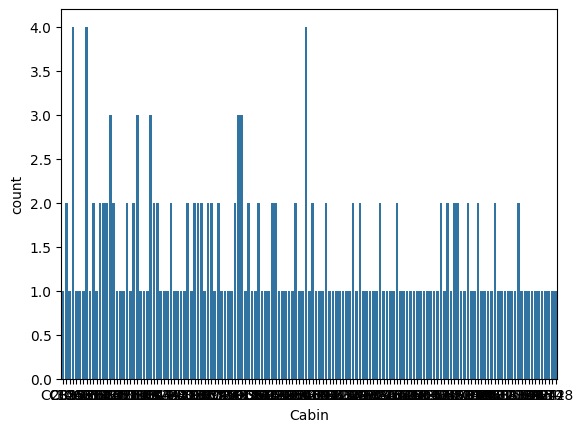

In [51]:
sns.countplot(data=df, x="Cabin")

In [62]:
x = df.drop(["Survived"], axis=1)

In [63]:
y = df["Survived"]

In [64]:
X_train, X_test, Y_train, Y_test = train_test_split(x,y, test_size=0.2, random_state=42)

In [65]:
cabin_imputer = SimpleImputer(missing_values=np.nan, strategy="constant",fill_value="Missing",add_indicator=True)

cabin_imputer.fit(X_train[["Cabin"]])

X_train[['Cabin',"cabin_missing_indicator"]] = cabin_imputer.transform(df[["Cabin"]])

X_test[['Cabin',"cabin_missing_indicator"]] = cabin_imputer.transform(X_test[["Cabin"]])

display(X_train)
display("--------------------")
display(X_test)

ValueError: Length of values (891) does not match length of index (712)

In [59]:
X_train.isnull().sum()

,0
PassengerId,0
Pclass,0
Name,0
Sex,0
Age,140
SibSp,0
Parch,0
Ticket,0
Fare,0
Cabin,553
